In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from rain2loss.hbv import DEFAULT_PARAMS, elevation_zones, run_hbv, water_balance_error
from rain2loss.lamah import load_attributes, load_hbv_inputs, load_lamah

GAUGE_ID = 824
attrs = load_attributes()
data = load_hbv_inputs(GAUGE_ID, attrs)
data.head()

,prec,temp,pet,qobs
1981-01-01,5.79,-0.8,0.132294,1.239931
1981-01-02,7.38,-2.9,0.066603,1.239931
1981-01-03,17.05,1.2,0.198097,1.506690
1981-01-04,6.27,-1.0,0.128818,1.686998
1981-01-05,2.39,-5.4,0.000000,1.400480


In [2]:
years = data.loc["1982":"2017"]
annual = years[["prec", "pet", "qobs"]].groupby(years.index.year).sum()
summary = annual.mean()
print(summary.round(0))
print("runoff ratio Q/P:", round(summary["qobs"] / summary["prec"], 2))
print("P - Q (mm/yr):", round(summary["prec"] - summary["qobs"]))

prec    1022.0
pet      525.0
qobs     537.0
dtype: float64
runoff ratio Q/P: 0.53
P - Q (mm/yr): 485


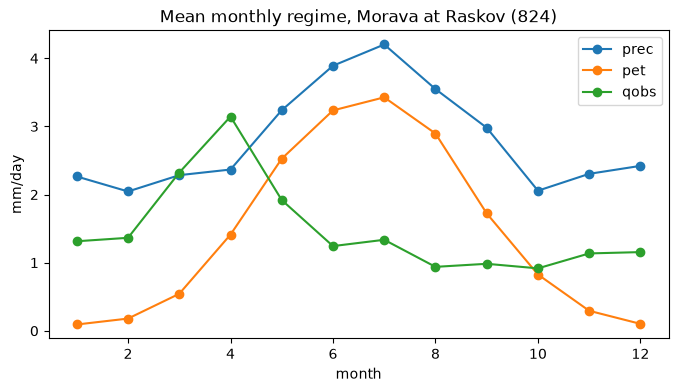

In [3]:
regime = data.groupby(data.index.month)[["prec", "pet", "qobs"]].mean()
ax = regime.plot(marker="o", figsize=(8, 4))
ax.set(xlabel="month", ylabel="mm/day", title="Mean monthly regime, Morava at Raskov (824)")
plt.show()

In [4]:
sim = run_hbv(data, DEFAULT_PARAMS)
states0 = [0.0, 0.0, 0.5 * DEFAULT_PARAMS["FC"], 0.0, 0.0]
print(f"water balance error: {water_balance_error(sim, states0):.2e} mm")
sim.head()

water balance error: -4.09e-12 mm


,p_in,melt,recharge,et_act,q0,q1,q2,q_gen,snow,liquid,sm,suz,slz,q_sim
1981-01-01,5.79,0.0,0.000000,0.094496,0.0,0.000000,0.000000,0.000000,5.790,0.000,124.905504,0.000000,0.000000,0.000000
1981-01-02,7.38,0.0,0.000000,0.047538,0.0,0.000000,0.000000,0.000000,13.170,0.000,124.857966,0.000000,0.000000,0.000000
1981-01-03,17.05,4.2,5.076693,0.158630,0.0,0.286135,0.030000,0.316135,8.970,0.897,139.975643,3.290558,1.470000,0.101163
1981-01-04,6.27,0.0,0.000000,0.103036,0.0,0.143245,0.059400,0.202645,15.415,0.722,139.872607,1.647313,2.910600,0.254528
1981-01-05,2.39,0.0,0.000000,0.000000,0.0,0.011785,0.088212,0.099997,18.527,0.000,139.872607,0.135528,4.322388,0.178877


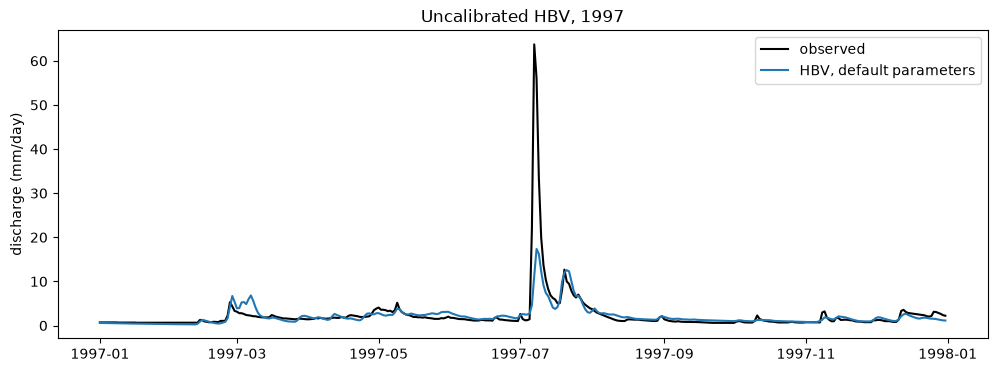

In [5]:
period = slice("1997-01-01", "1997-12-31")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(data.loc[period, "qobs"], color="black", label="observed")
ax.plot(sim.loc[period, "q_sim"], color="tab:blue", label="HBV, default parameters")
ax.set(ylabel="discharge (mm/day)", title="Uncalibrated HBV, 1997")
ax.legend()
plt.show()

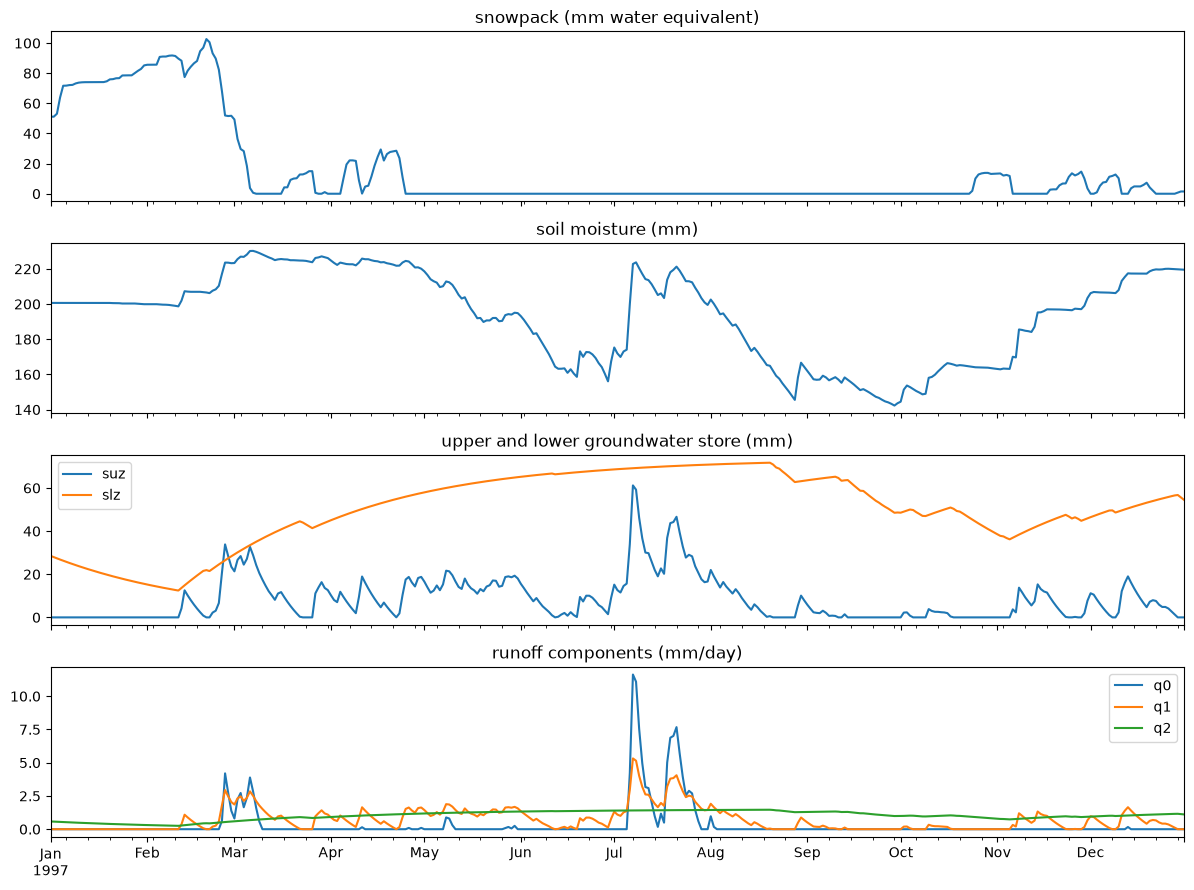

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
sim.loc[period, "snow"].plot(ax=axes[0], title="snowpack (mm water equivalent)")
sim.loc[period, "sm"].plot(ax=axes[1], title="soil moisture (mm)")
sim.loc[period, ["suz", "slz"]].plot(ax=axes[2], title="upper and lower groundwater store (mm)")
sim.loc[period, ["q0", "q1", "q2"]].plot(ax=axes[3], title="runoff components (mm/day)")
plt.tight_layout()
plt.show()

In [7]:
for fc in [100, 250, 450]:
    params = {**DEFAULT_PARAMS, "FC": fc}
    out = run_hbv(data, params).loc["1982":"2017"]
    print(f"FC = {fc:3d} mm -> Q = {out['q_sim'].mean() * 365:4.0f} mm/yr, "
          f"ET = {out['et_act'].mean() * 365:4.0f} mm/yr")

FC = 100 mm -> Q =  576 mm/yr, ET =  449 mm/yr
FC = 250 mm -> Q =  553 mm/yr, ET =  471 mm/yr
FC = 450 mm -> Q =  535 mm/yr, ET =  490 mm/yr


zone offsets (m): [-192.    0.  192.]


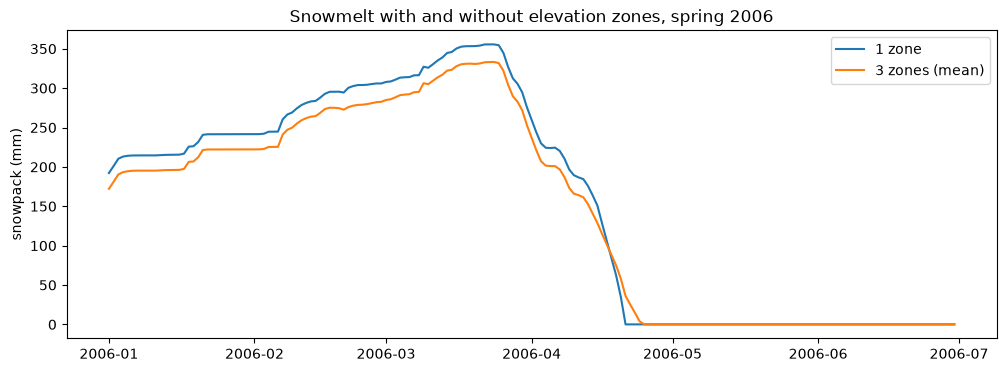

In [8]:
zones = elevation_zones(attrs.loc[GAUGE_ID, "elev_mean"], attrs.loc[GAUGE_ID, "elev_std"], n_zones=3)
print("zone offsets (m):", zones.round(0))
sim3 = run_hbv(data, DEFAULT_PARAMS, zones)

spring = slice("2006-01-01", "2006-06-30")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sim.loc[spring, "snow"], label="1 zone")
ax.plot(sim3.loc[spring, "snow"], label="3 zones (mean)")
ax.set(ylabel="snowpack (mm)", title="Snowmelt with and without elevation zones, spring 2006")
ax.legend()
plt.show()

In [9]:
era5_et = load_lamah(GAUGE_ID, attrs)["total_et"].loc["1982":"2017"]
print("ERA5-Land actual ET:", round(era5_et.mean() * 365), "mm/yr")
print("HBV actual ET      :", round(sim["et_act"].loc["1982":"2017"].mean() * 365), "mm/yr")
print("P - Q              :", round(summary["prec"] - summary["qobs"]), "mm/yr")

ERA5-Land actual ET: 543 mm/yr
HBV actual ET      : 471 mm/yr
P - Q              : 485 mm/yr
